<a href="https://colab.research.google.com/github/nidhish4616-collab/DSV_Week1_to_Week4_Renewable_Enegry/blob/main/DSV_Week6_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 – Feature Engineering

**Course:** 24ADI204 – Data Science and Visualization  
**Dataset:** NewsData.io Renewable Energy News Dataset  
**Aim:** Perform feature engineering, skewness correction, normalization, scaling and categorical encoding on the renewable-energy news dataset.
TEAM MEMBERS:

*   Nagul Nishoke K.S           25BAD063
*   Nidhish.V                   25BAD067
*   Nirmal B                    25BAD068
*   Nivesh S                    25BAD073







## Step 1: Import libraries

In [ ]:
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load the new dataset

Upload `NewsData.io_Renewable_Energy.csv (1).zip` or the extracted CSV file. This cell reads either format and creates the DataFrame `df`.

In [ ]:
uploaded = files.upload()
filename = next(iter(uploaded))
file_bytes = uploaded[filename]

if filename.lower().endswith(".zip"):
    with zipfile.ZipFile(io.BytesIO(file_bytes)) as z:
        csv_files = [name for name in z.namelist() if name.lower().endswith(".csv")]
        if not csv_files:
            raise ValueError("The ZIP file does not contain a CSV file.")
        with z.open(csv_files[0]) as f:
            df = pd.read_csv(f)
elif filename.lower().endswith(".csv"):
    df = pd.read_csv(io.BytesIO(file_bytes))
else:
    raise ValueError("Please upload a ZIP or CSV file.")

print("Dataset loaded successfully.")
print("File:", filename)
print("Dataset shape:", df.shape)
display(df.head())

Saving NewsData_Renewable_Energy_Final.csv to NewsData_Renewable_Energy_Final.csv
Dataset loaded successfully.
File: NewsData_Renewable_Energy_Final.csv
Dataset shape: (3754, 25)


,article_id,title,link,keywords,creator,description,content,pubDate,image_url,source_id,...,language,ai_tag,ai_region,sentiment,sentiment_stats,Year,Title_Length,Description_Length,Content_Length,Keyword_Count
0,34fa2a78349418b971cbce5686908804,Saudi sovereign wealth fund pitches kingdom as...,https://www.brecorder.com/news/40290372/saudi-...,markets,none@none.com (Reuters),MIAMI: The head of Saudi Arabia’s Public Inves...,MIAMI: The head of Saudi Arabia’s Public Inves...,2024-02-23 09:50:34,https://i.brecorder.com/large/2024/02/23145001...,brecorder,...,english,artificial intelligence,"miami,florida,united states of america,north a...",neutral,"positive:0.06,neutral:99.85,negative:0.09",2024,53,1672,1672,1
1,9a28fd4fd309b17db653ea86e4c7b8c1,Govt Amends Electricity Rules To Further Empow...,https://odishabytes.com/govt-amends-electricit...,india,OB Bureau,New Delhi: The Union government has amended th...,New Delhi: The Union government has amended th...,2024-02-23 09:12:16,https://odishabytes.com/wp-content/uploads/202...,odishabytes,...,english,"renewable energy,energy","new delhi,delhi,india,asia",neutral,"positive:0.84,neutral:99.03,negative:0.13",2024,82,468,4730,1
2,81bdbec184bb3cfa549c1d75dd1ef4a9,CIP's journey through offshore wind turbulence,https://www.digitimes.com/news/a20240222VL204/...,sustainability,DIGITIMES,The offshore wind power industry is navigating...,The offshore wind power industry is navigating...,2024-02-23 08:42:05,https://img.digitimes.com/newsshow/20240222vl2...,digitimes,...,english,"renewable energy,energy",Unknown,neutral,"positive:3.73,neutral:95.96,negative:0.32",2024,46,567,2351,1
3,e9c00bb7e42f0ee78d40221608feb878,BIAL ties up with CleanMax for 45.9 MW solar-w...,https://www.thehindu.com/business/bial-ties-up...,business,Unknown,They have signed a 25-year long-term power pur...,Clean Max Enviro Energy Solutions (CleanMax) a...,2024-02-23 07:27:52,https://th-i.thgim.com/public/incoming/3e6mg1/...,thehindu,...,english,"renewable energy,energy","bengaluru,karnataka,india,asia",positive,"positive:92.32,neutral:7.3,negative:0.38",2024,84,159,1990,1
4,d0acebec6222d82a927acae52d3664a3,Union Power and New & Renewable Energy Ministe...,https://orissadiary.com/union-power-and-new-re...,"national,top news,ministry of power",Odisha Diary bureau,The Government of India has approved amendment...,The Government of India has approved amendment...,2024-02-23 07:22:55,https://orissadiary.com/wp-content/uploads/202...,orissadiary,...,english,"renewable energy,energy",Unknown,positive,"positive:53.9,neutral:45.47,negative:0.63",2024,160,356,5167,3


## Step 3: Inspect dataset columns

Check that the columns required for Week 6 feature engineering are present.

In [ ]:
print("Dataset columns:")
print(df.columns.tolist())

required_columns = [
    "title", "description", "content", "keywords",
    "pubDate", "source_priority", "category", "sentiment", "language"
]

missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError("Required columns missing from dataset: " + str(missing_columns))

print("\nAll required columns are available.")

Dataset columns:
['article_id', 'title', 'link', 'keywords', 'creator', 'description', 'content', 'pubDate', 'image_url', 'source_id', 'source_url', 'source_icon', 'source_priority', 'country', 'category', 'language', 'ai_tag', 'ai_region', 'sentiment', 'sentiment_stats', 'Year', 'Title_Length', 'Description_Length', 'Content_Length', 'Keyword_Count']

All required columns are available.


## Step 4: Create new features

Create article title length, description length, content length, keyword count, publication year and month. These features convert text and date information into useful numerical variables.

In [ ]:
df_week6 = df.copy()

df_week6["Title_Length"] = df_week6["title"].fillna("").astype(str).str.len()
df_week6["Description_Length"] = df_week6["description"].fillna("").astype(str).str.len()
df_week6["Content_Length"] = df_week6["content"].fillna("").astype(str).str.len()

df_week6["Keyword_Count"] = df_week6["keywords"].fillna("").astype(str).apply(
    lambda x: 0 if x.strip() == "" else len([v for v in x.split(",") if v.strip()])
)

date = pd.to_datetime(df_week6["pubDate"], errors="coerce", utc=True)
df_week6["Year"] = date.dt.year
df_week6["Month"] = date.dt.month
df_week6["source_priority"] = pd.to_numeric(
    df_week6["source_priority"], errors="coerce"
)

new_features = [
    "Title_Length", "Description_Length", "Content_Length",
    "Keyword_Count", "Year", "Month", "source_priority"
]
display(df_week6[new_features].head())
print("New numerical features created.")

,Title_Length,Description_Length,Content_Length,Keyword_Count,Year,Month,source_priority
0,53,1672,1672,1,2024,2,384715
1,82,468,4730,1,2024,2,512881
2,46,567,2351,1,2024,2,163335
3,84,159,1990,1,2024,2,2972
4,160,356,5167,3,2024,2,2836164


New numerical features created.


## Step 5: Prepare numerical features

Select the numerical features, replace infinite values and fill missing values using the median. This prepares the data for statistical analysis and scaling.

In [ ]:
feature_columns = [
    "source_priority", "Year", "Month", "Title_Length",
    "Description_Length", "Content_Length", "Keyword_Count"
]

X = df_week6[feature_columns].replace([np.inf, -np.inf], np.nan).copy()
X = X.fillna(X.median()).fillna(0)

print("Numerical features:")
print(feature_columns)
display(X.describe().round(2))

Numerical features:
['source_priority', 'Year', 'Month', 'Title_Length', 'Description_Length', 'Content_Length', 'Keyword_Count']


,source_priority,Year,Month,Title_Length,Description_Length,Content_Length,Keyword_Count
count,3.754000e+03,3754.00,3754.00,3754.00,3754.00,3754.00,3754.00
mean,3.218495e+06,2023.91,2.38,75.82,1539.18,3071.19,12.04
std,3.303692e+07,0.28,3.00,26.60,2889.91,4193.07,67.95
min,1.400000e+01,2023.00,1.00,10.00,7.00,1.00,1.00
25%,1.336100e+04,2024.00,1.00,58.00,198.00,167.00,1.00
50%,1.677790e+05,2024.00,2.00,72.00,337.00,2126.50,1.00
75%,4.587220e+05,2024.00,2.00,90.00,1088.25,4266.00,3.00
max,7.483337e+08,2024.00,12.00,249.00,35830.00,79765.00,1068.00


## Step 6: Calculate skewness

Skewness measures how asymmetric a numerical feature's distribution is. A value near zero indicates a more symmetric distribution.

In [ ]:
print("Skewness before transformation:")
display(X.skew().to_frame(name="Skewness").round(3))

Skewness before transformation:


,Skewness
source_priority,21.491
Year,-2.942
Month,2.809
Title_Length,1.140
Description_Length,3.426
Content_Length,5.882
Keyword_Count,8.189


## Step 7: Visualize distribution before transformation

The histogram and KDE curve show the original distribution of article content length.

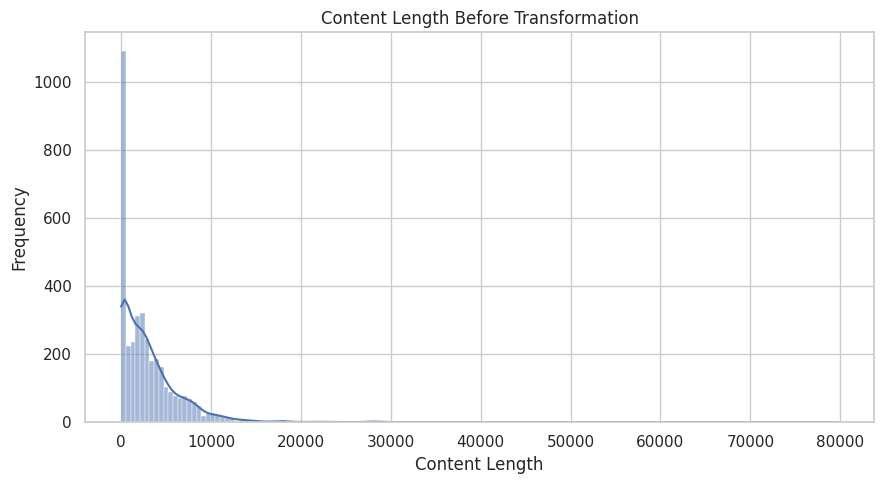

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(X["Content_Length"], kde=True)
plt.title("Content Length Before Transformation")
plt.xlabel("Content Length")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 8: Apply skewness correction

Use `log1p()` on non-negative numerical features to reduce positive skewness. The original columns are kept unchanged; transformed values are stored in new columns.

In [ ]:
skew_features = [
    "Title_Length", "Description_Length", "Content_Length", "Keyword_Count"
]

for col in skew_features:
    df_week6[col + "_Log"] = np.log1p(X[col].clip(lower=0))

print("Skewness after log transformation:")
display(df_week6[[col + "_Log" for col in skew_features]].skew().to_frame(
    name="Skewness"
).round(3))

Skewness after log transformation:


,Skewness
Title_Length_Log,-0.438
Description_Length_Log,0.125
Content_Length_Log,-0.893
Keyword_Count_Log,3.248


## Step 9: Visualize distribution after transformation

Compare the content-length distribution after log transformation.

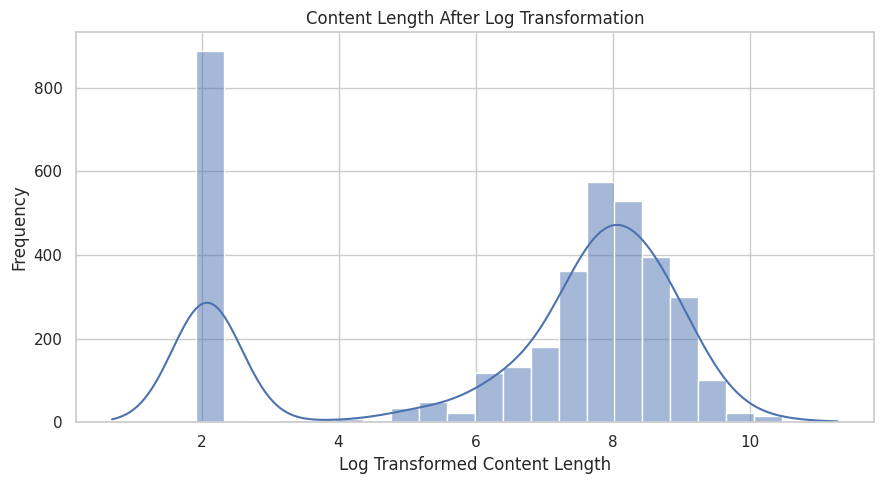

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(df_week6["Content_Length_Log"], kde=True)
plt.title("Content Length After Log Transformation")
plt.xlabel("Log Transformed Content Length")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

## Step 10: One-Hot Encoding

One-Hot Encoding converts category and sentiment labels into separate binary columns. Missing labels are marked as `Unknown`.

In [ ]:
category_values = df_week6["category"].fillna("Unknown").astype(str)
sentiment_values = df_week6["sentiment"].fillna("Unknown").astype(str)

category_encoded = pd.get_dummies(
    category_values, prefix="Category", dtype=int
)
sentiment_encoded = pd.get_dummies(
    sentiment_values, prefix="Sentiment", dtype=int
)

df_week6 = pd.concat(
    [df_week6, category_encoded, sentiment_encoded], axis=1
)

print("One-Hot Encoding completed.")
print("New One-Hot columns:", len(category_encoded.columns) + len(sentiment_encoded.columns))
display(df_week6[list(category_encoded.columns) + list(sentiment_encoded.columns)].head())

One-Hot Encoding completed.
New One-Hot columns: 26


,Category_business,Category_entertainment,"Category_entertainment,environment,food",Category_environment,"Category_environment,health,politics,business",Category_health,"Category_health,food","Category_health,science",Category_other,Category_politics,...,"Category_technology,science",Category_top,"Category_top,world,environment,health",Category_tourism,Category_world,"Category_world,top,environment,health",Sentiment_Unknown,Sentiment_negative,Sentiment_neutral,Sentiment_positive
0,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
1,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
3,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
4,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1


## Step 11: Label Encoding

Label Encoding assigns a numerical label to each language category.

In [ ]:
label_encoder = LabelEncoder()

df_week6["Language_Encoded"] = label_encoder.fit_transform(
    df_week6["language"].fillna("Unknown").astype(str)
)

print("Language label mapping:")
print(dict(zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
)))

display(df_week6[["language", "Language_Encoded"]].head(10))

Language label mapping:
{'arabic': np.int64(0), 'azerbaijani': np.int64(1), 'bengali': np.int64(2), 'bulgarian': np.int64(3), 'chinese': np.int64(4), 'danish': np.int64(5), 'dutch': np.int64(6), 'english': np.int64(7), 'filipino': np.int64(8), 'french': np.int64(9), 'german': np.int64(10), 'greek': np.int64(11), 'gujarati': np.int64(12), 'hindi': np.int64(13), 'hungarian': np.int64(14), 'indonesian': np.int64(15), 'italian': np.int64(16), 'korean': np.int64(17), 'malay': np.int64(18), 'malayalam': np.int64(19), 'maori': np.int64(20), 'marathi': np.int64(21), 'oriya': np.int64(22), 'persian': np.int64(23), 'polish': np.int64(24), 'portuguese': np.int64(25), 'punjabi': np.int64(26), 'russian': np.int64(27), 'spanish': np.int64(28), 'telugu': np.int64(29), 'thai': np.int64(30), 'turkish': np.int64(31), 'urdu': np.int64(32), 'vietnamese': np.int64(33)}


,language,Language_Encoded
0,english,7
1,english,7
2,english,7
3,english,7
4,english,7
5,english,7
6,english,7
7,english,7
8,english,7
9,english,7


## Step 12: Min-Max Normalization

Min-Max Scaling converts each selected numerical feature to a range between 0 and 1.

In [ ]:
minmax_scaler = MinMaxScaler()
minmax_values = minmax_scaler.fit_transform(X)

minmax_columns = [col + "_MinMax" for col in feature_columns]
df_week6[minmax_columns] = minmax_values

print("Min-Max normalized values:")
display(df_week6[minmax_columns].head())
print("\nMinimum values:")
print(df_week6[minmax_columns].min().round(2))
print("\nMaximum values:")
print(df_week6[minmax_columns].max().round(2))

Min-Max normalized values:


,source_priority_MinMax,Year_MinMax,Month_MinMax,Title_Length_MinMax,Description_Length_MinMax,Content_Length_MinMax,Keyword_Count_MinMax
0,0.000514,1.0,0.090909,0.179916,0.046479,0.020949,0.000000
1,0.000685,1.0,0.090909,0.301255,0.012869,0.059287,0.000000
2,0.000218,1.0,0.090909,0.150628,0.015632,0.029462,0.000000
3,0.000004,1.0,0.090909,0.309623,0.004243,0.024936,0.000000
4,0.003790,1.0,0.090909,0.627615,0.009742,0.064766,0.001874



Minimum values:
source_priority_MinMax       0.0
Year_MinMax                  0.0
Month_MinMax                 0.0
Title_Length_MinMax          0.0
Description_Length_MinMax    0.0
Content_Length_MinMax        0.0
Keyword_Count_MinMax         0.0
dtype: float64

Maximum values:
source_priority_MinMax       1.0
Year_MinMax                  1.0
Month_MinMax                 1.0
Title_Length_MinMax          1.0
Description_Length_MinMax    1.0
Content_Length_MinMax        1.0
Keyword_Count_MinMax         1.0
dtype: float64


## Step 13: Standardization

StandardScaler transforms each selected feature to have approximately zero mean and unit standard deviation.

In [ ]:
standard_scaler = StandardScaler()
standard_values = standard_scaler.fit_transform(X)

standard_columns = [col + "_Standard" for col in feature_columns]
df_week6[standard_columns] = standard_values

print("Standardized values:")
display(df_week6[standard_columns].head())
print("\nMeans after standardization:")
print(df_week6[standard_columns].mean().round(2))

Standardized values:


,source_priority_Standard,Year_Standard,Month_Standard,Title_Length_Standard,Description_Length_Standard,Content_Length_Standard,Keyword_Count_Standard
0,-0.085788,0.307863,-0.125063,-0.858005,0.045965,-0.333736,-0.162534
1,-0.081908,0.307863,-0.125063,0.232543,-0.370712,0.395660,-0.162534
2,-0.092489,0.307863,-0.125063,-1.121241,-0.336451,-0.171780,-0.162534
3,-0.097344,0.307863,-0.125063,0.307753,-0.477650,-0.257886,-0.162534
4,-0.011574,0.307863,-0.125063,3.165740,-0.409473,0.499894,-0.133098



Means after standardization:
source_priority_Standard       0.0
Year_Standard                  0.0
Month_Standard                 0.0
Title_Length_Standard          0.0
Description_Length_Standard    0.0
Content_Length_Standard        0.0
Keyword_Count_Standard        -0.0
dtype: float64


## Step 14: Compare before and after scaling

The two histograms show the original content length and its Min-Max normalized values.

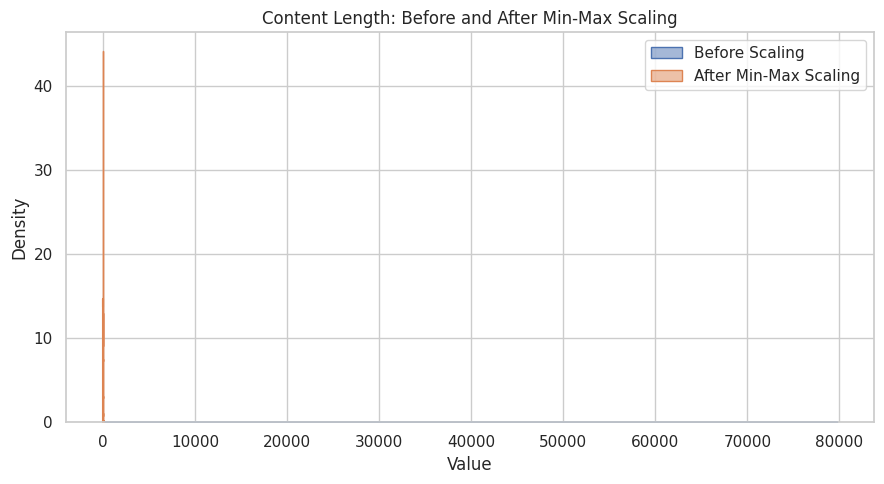

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(X["Content_Length"], label="Before Scaling",
             kde=True, stat="density", element="step")
sns.histplot(df_week6["Content_Length_MinMax"], label="After Min-Max Scaling",
             kde=True, stat="density", element="step")
plt.title("Content Length: Before and After Min-Max Scaling")
plt.xlabel("Value")
plt.legend()
plt.tight_layout()
plt.show()

## Step 15: Final feature engineering report

Display the dataset dimensions, missing-value count and summary of the transformed numerical features.

In [ ]:
print("WEEK 6 - FEATURE ENGINEERING REPORT")
print("===================================")
print("Original dataset shape:", df.shape)
print("Final dataset shape:", df_week6.shape)
print("Total missing values:", df_week6.isnull().sum().sum())

print("\nSummary of normalized features:")
display(df_week6[minmax_columns].describe().round(3))

print("\nWeek 6 feature engineering completed successfully.")

# Save the transformed dataset for later use.
df_week6.to_csv("Week6_Feature_Engineered_Data.csv", index=False)
print("Saved: Week6_Feature_Engineered_Data.csv")

WEEK 6 - FEATURE ENGINEERING REPORT
Original dataset shape: (3754, 25)
Final dataset shape: (3754, 71)
Total missing values: 0

Summary of normalized features:


,source_priority_MinMax,Year_MinMax,Month_MinMax,Title_Length_MinMax,Description_Length_MinMax,Content_Length_MinMax,Keyword_Count_MinMax
count,3754.000,3754.000,3754.000,3754.000,3754.000,3754.000,3754.000
mean,0.004,0.913,0.125,0.275,0.043,0.038,0.010
std,0.044,0.281,0.273,0.111,0.081,0.053,0.064
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,1.000,0.000,0.201,0.005,0.002,0.000
50%,0.000,1.000,0.091,0.259,0.009,0.027,0.000
75%,0.001,1.000,0.091,0.335,0.030,0.053,0.002
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000



Week 6 feature engineering completed successfully.
Saved: Week6_Feature_Engineered_Data.csv


## Conclusion

Feature engineering was performed on the renewable-energy news dataset. New numerical features were created from article text and publication dates. Skewness was examined and log transformation was applied to selected features. Categorical variables were converted using One-Hot Encoding and Label Encoding. Min-Max Normalization and Standardization were also performed and visualized.